In [31]:

import os
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models
from IPython.display import Audio, display

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Keras version:", tf.keras.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.22.0-rc0
Keras version: 3.16.0.dev2026102204
Available GPUs: []


In [32]:

DATASET_PATH = pathlib.Path("data/mini_speech_commands_extracted/mini_speech_commands")

if not DATASET_PATH.exists():
    tf.keras.utils.get_file(
        fname="mini_speech_commands.zip",
        origin="https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip",
        extract=True,
        cache_dir=".",
        cache_subdir="data"
    )

commands = sorted([
    folder.name
    for folder in DATASET_PATH.iterdir()
    if folder.is_dir()
])

print("Commands:", commands)
print("Number of classes:", len(commands))

for command in commands:
    count = len(list((DATASET_PATH / command).glob("*.wav")))
    print(f"{command}: {count} recordings")


Commands: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
Number of classes: 8
down: 1000 recordings
go: 1000 recordings
left: 1000 recordings
no: 1000 recordings
right: 1000 recordings
stop: 1000 recordings
up: 1000 recordings
yes: 1000 recordings


Audio shape: (16000,)
Sampling rate: 16000
Audio dtype: <dtype: 'float32'>
Duration: 1.0 seconds


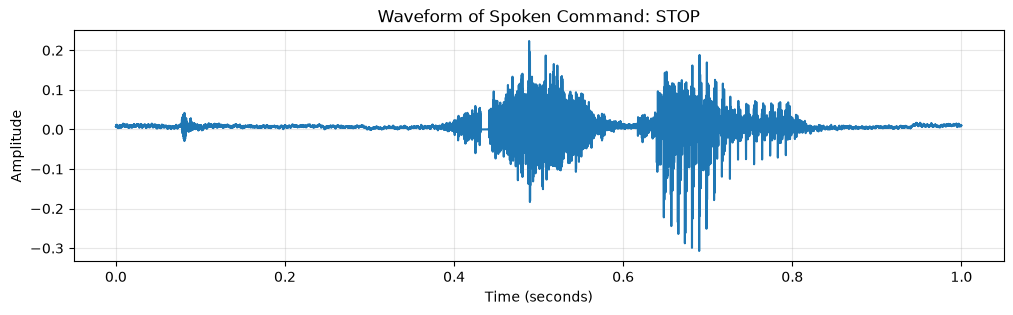

In [33]:

# Select one audio recording
audio_path = next((DATASET_PATH / "stop").glob("*.wav"))

# Read the audio file
audio_binary = tf.io.read_file(str(audio_path))

# Decode WAV into a tensor
audio, sample_rate = tf.audio.decode_wav(audio_binary)

# Remove the single channel dimension
audio = tf.squeeze(audio, axis=-1)

print("Audio shape:", audio.shape)
print("Sampling rate:", sample_rate.numpy())
print("Audio dtype:", audio.dtype)
print("Duration:", len(audio) / sample_rate.numpy(), "seconds")

# Listen to the recording
display(Audio(audio.numpy(), rate=int(sample_rate.numpy())))

# Visualize waveform
plt.figure(figsize=(12, 3))
time_axis = np.arange(len(audio)) / sample_rate.numpy()

plt.plot(time_axis, audio.numpy())
plt.title("Waveform of Spoken Command: STOP")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)
plt.show()


Waveform shape: (16000,)
Spectrogram shape: (124, 129)


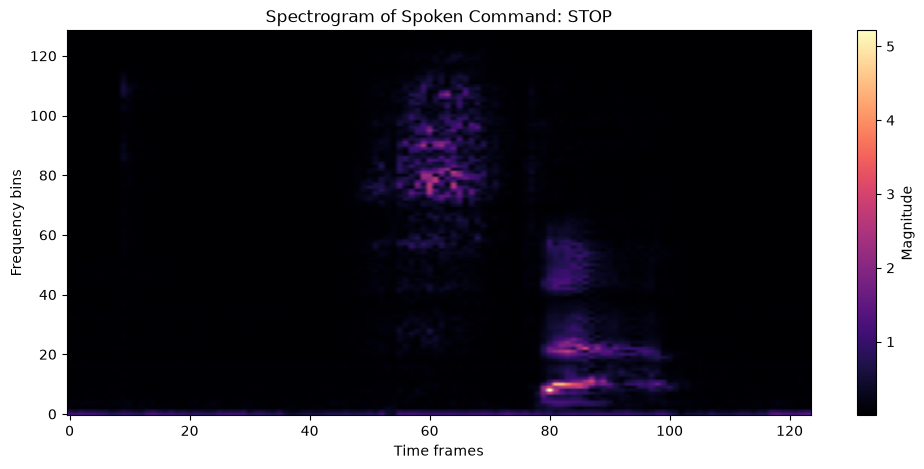

In [34]:

# Convert the waveform into a spectrogram
spectrogram = tf.signal.stft(
    audio,
    frame_length=255,
    frame_step=128
)

# Convert complex STFT output to magnitude
spectrogram = tf.abs(spectrogram)

print("Waveform shape:", audio.shape)
print("Spectrogram shape:", spectrogram.shape)

# Plot spectrogram
plt.figure(figsize=(12, 5))

plt.imshow(
    spectrogram.numpy().T,
    aspect="auto",
    origin="lower",
    cmap="magma"
)

plt.title("Spectrogram of Spoken Command: STOP")
plt.xlabel("Time frames")
plt.ylabel("Frequency bins")
plt.colorbar(label="Magnitude")
plt.show()


In [35]:
#standardizing the length of the audio recordings to 1 second (16000 samples)


def load_audio(file_path):
    audio_binary = tf.io.read_file(file_path)

    waveform, sample_rate = tf.audio.decode_wav(
        audio_binary,
        desired_channels=1
    )

    waveform = tf.squeeze(waveform, axis=-1)

    # Pad short recordings or truncate long recordings
    waveform = waveform[:16000]

    padding = tf.maximum(16000 - tf.shape(waveform)[0], 0)

    waveform = tf.pad(
        waveform,
        paddings=[[0, padding]]
    )

    return waveform

# Test the function using our STOP recording
processed_audio = load_audio(str(audio_path))

print("Original shape:", audio.shape)
print("Processed shape:", processed_audio.shape)
print("Data type:", processed_audio.dtype)


Original shape: (16000,)
Processed shape: (16000,)
Data type: <dtype: 'float32'>


In [36]:

# Create numerical labels for commands
label_mapping = {
    command: index
    for index, command in enumerate(commands)
}

# Collect all audio file paths and their labels
file_paths = []
labels = []

for command in commands:
    for file_path in (DATASET_PATH / command).glob("*.wav"):
        file_paths.append(str(file_path))
        labels.append(label_mapping[command])

file_paths = np.array(file_paths)
labels = np.array(labels)

print("Label mapping:", label_mapping)
print("Total recordings:", len(file_paths))
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])
print("Unique labels:", np.unique(labels))


Label mapping: {'down': 0, 'go': 1, 'left': 2, 'no': 3, 'right': 4, 'stop': 5, 'up': 6, 'yes': 7}
Total recordings: 8000
Labels shape: (8000,)
First 10 labels: [0 0 0 0 0 0 0 0 0 0]
Unique labels: [0 1 2 3 4 5 6 7]


In [37]:

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Second split: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", len(X_train), len(y_train))
print("Validation:", len(X_val), len(y_val))
print("Testing:", len(X_test), len(y_test))

print("\nTraining class counts:", np.bincount(y_train))
print("Validation class counts:", np.bincount(y_val))
print("Testing class counts:", np.bincount(y_test))


Training: 5600 5600
Validation: 1200 1200
Testing: 1200 1200

Training class counts: [700 700 700 700 700 700 700 700]
Validation class counts: [150 150 150 150 150 150 150 150]
Testing class counts: [150 150 150 150 150 150 150 150]


In [38]:

# Convert a waveform into a CNN-ready spectrogram
def get_spectrogram(waveform):
    spectrogram = tf.signal.stft(
        waveform,
        frame_length=255,
        frame_step=128
    )

    spectrogram = tf.abs(spectrogram)

    # Add a channel dimension for Conv2D
    spectrogram = spectrogram[..., tf.newaxis]

    return spectrogram


# Load an audio file and return its spectrogram and label
def preprocess_audio(file_path, label):
    waveform = load_audio(file_path)
    spectrogram = get_spectrogram(waveform)

    return spectrogram, label


# Test on a single recording
sample_spectrogram, sample_label = preprocess_audio(
    X_train[0],
    y_train[0]
)

print("Spectrogram shape:", sample_spectrogram.shape)
print("Label:", int(sample_label))
print("Command:", commands[int(sample_label)])


Spectrogram shape: (124, 129, 1)
Label: 2
Command: left


In [39]:

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def create_dataset(file_paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (file_paths, labels)
    )

    # Convert WAV files into spectrograms
    dataset = dataset.map(
        preprocess_audio,
        num_parallel_calls=AUTOTUNE
    )

    # Cache preprocessed data
    dataset = dataset.cache()

    # Shuffle only the training dataset
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(file_paths),
            seed=42
        )

    # Create batches
    dataset = dataset.batch(BATCH_SIZE)

    # Prepare upcoming batches
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

print("Datasets created successfully!")


Datasets created successfully!


In [40]:

for spectrogram_batch, label_batch in train_ds.take(1):
    print("Batch spectrogram shape:", spectrogram_batch.shape)
    print("Batch labels shape:", label_batch.shape)
    print("First 10 labels:", label_batch.numpy()[:10])


Batch spectrogram shape: (32, 124, 129, 1)
Batch labels shape: (32,)
First 10 labels: [5 1 6 7 1 6 7 3 6 2]


In [41]:

model = tf.keras.Sequential([
    layers.Input(shape=(124, 129, 1)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dense(8, activation="softmax")
])

model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 124, 129, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 62, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 62, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 31, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,496 (91.78 KB)

 Trainable params: 23,496 (91.78 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:

model = tf.keras.Sequential([
    layers.Input(shape=(124, 129, 1)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dense(8, activation="softmax")
])

model.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 124, 129, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 62, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 62, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 31, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,496 (91.78 KB)

 Trainable params: 23,496 (91.78 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully!")
print("Optimizer:", model.optimizer.__class__.__name__)
print("Learning rate:", float(model.optimizer.learning_rate.numpy()))
print("Loss:", model.loss.__class__.__name__)


Model compiled successfully!
Optimizer: Adam
Learning rate: 0.0010000000474974513
Loss: SparseCategoricalCrossentropy


In [44]:

# Stop training if validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# Train the CNN
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping],
    verbose=1
)

print("Training completed!")
print("Epochs trained:", len(history.history["loss"]))


Epoch 1/20


c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


175/175 ━━━━━━━━━━━━━━━━━━━━ 40s 217ms/step - accuracy: 0.1363 - loss: 2.0774 - val_accuracy: 0.1900 - val_loss: 2.0645
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 36s 203ms/step - accuracy: 0.1996 - loss: 2.0228 - val_accuracy: 0.2317 - val_loss: 1.9866
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 32s 183ms/step - accuracy: 0.2370 - loss: 1.9452 - val_accuracy: 0.2808 - val_loss: 1.9135
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 35s 198ms/step - accuracy: 0.2784 - loss: 1.8793 - val_accuracy: 0.3183 - val_loss: 1.8655
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 35s 202ms/step - accuracy: 0.3336 - loss: 1.8107 - val_accuracy: 0.2733 - val_loss: 1.8798
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 36s 203ms/step - accuracy: 0.3455 - loss: 1.7493 - val_accuracy: 0.3983 - val_loss: 1.7275
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 34s 195ms/step - accuracy: 0.3795 - loss: 1.7005 - val_accuracy: 0.3958 - val_loss: 1.6543
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 34s 192ms/step - accuracy: 0.4096 - loss: 1.6340 - val

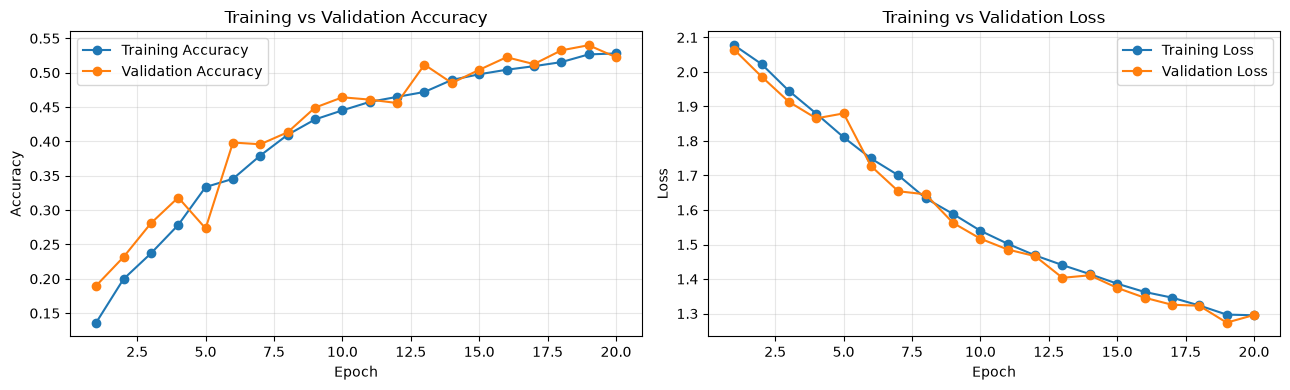

Best validation-loss epoch: 19
Best validation accuracy: 0.5400000214576721


In [45]:

epochs = range(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Accuracy
axes[0].plot(epochs, history.history["accuracy"],
             label="Training Accuracy", marker="o")
axes[0].plot(epochs, history.history["val_accuracy"],
             label="Validation Accuracy", marker="o")

axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(epochs, history.history["loss"],
             label="Training Loss", marker="o")
axes[1].plot(epochs, history.history["val_loss"],
             label="Validation Loss", marker="o")

axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_epoch = np.argmin(history.history["val_loss"]) + 1
print("Best validation-loss epoch:", best_epoch)
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))


In [46]:
# due to overfiiting rebuilding the model with architecture


model_v2 = tf.keras.Sequential([
    layers.Input(shape=(124, 129, 1)),

    # Reduce scale of spectrogram magnitudes
    layers.Rescaling(1.0 / 10.0),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(8, activation="softmax")
])

model_v2.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 124, 129, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 124, 129, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 62, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 62, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 31, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 31, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 15360)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │     1,966,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,022,984 (7.72 MB)

 Trainable params: 2,022,984 (7.72 MB)

 Non-trainable params: 0 (0.00 B)

In [47]:
# as there is approx 20 lakh parameter we need to rebuild again by reducing spatial dimensions
model_v2 = tf.keras.Sequential([
    layers.Input(shape=(124, 129, 1)),

    layers.Rescaling(1.0 / 10.0),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),

    # Reduce spatial dimensions before Flatten
    layers.AveragePooling2D(pool_size=(3, 3)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(8, activation="softmax")
])

model_v2.summary()


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 124, 129, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 124, 129, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 62, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 62, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 31, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 31, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 261,704 (1022.28 KB)

 Trainable params: 261,704 (1022.28 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:

# Compile Model V2
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

# Early stopping
early_stopping_v2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train Model V2
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[early_stopping_v2],
    verbose=1
)

print("\nTraining completed!")
print("Epochs trained:", len(history_v2.history["loss"]))
print("Best validation accuracy:",
      max(history_v2.history["val_accuracy"]))
print("Lowest validation loss:",
      min(history_v2.history["val_loss"]))


Epoch 1/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 45s 247ms/step - accuracy: 0.3366 - loss: 1.7923 - val_accuracy: 0.5067 - val_loss: 1.3911
Epoch 2/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 44s 252ms/step - accuracy: 0.5736 - loss: 1.2107 - val_accuracy: 0.6558 - val_loss: 0.9830
Epoch 3/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 42s 242ms/step - accuracy: 0.6787 - loss: 0.8988 - val_accuracy: 0.7042 - val_loss: 0.8759
Epoch 4/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 43s 245ms/step - accuracy: 0.7412 - loss: 0.7310 - val_accuracy: 0.7700 - val_loss: 0.7039
Epoch 5/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 43s 243ms/step - accuracy: 0.7868 - loss: 0.6210 - val_accuracy: 0.7942 - val_loss: 0.6484
Epoch 6/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 43s 248ms/step - accuracy: 0.8048 - loss: 0.5598 - val_accuracy: 0.8075 - val_loss: 0.5571
Epoch 7/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 43s 246ms/step - accuracy: 0.8232 - loss: 0.4996 - val_accuracy: 0.8292 - val_loss: 0.5223
Epoch 8/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 43s 246ms/step - accuracy: 0.8454 - loss: 0

In [49]:

# Evaluate the best restored V2 weights
test_loss, test_accuracy = model_v2.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 202ms/step - accuracy: 0.8817 - loss: 0.4645
Test Accuracy: 88.17%
Test Loss: 0.4645


38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step
Classification Report:

              precision    recall  f1-score   support

        down      0.902     0.793     0.844       150
          go      0.747     0.787     0.766       150
        left      0.903     0.927     0.914       150
          no      0.804     0.847     0.825       150
       right      0.971     0.900     0.934       150
        stop      0.978     0.880     0.926       150
          up      0.836     0.953     0.891       150
         yes      0.948     0.967     0.957       150

    accuracy                          0.882      1200
   macro avg      0.886     0.882     0.882      1200
weighted avg      0.886     0.882     0.882      1200



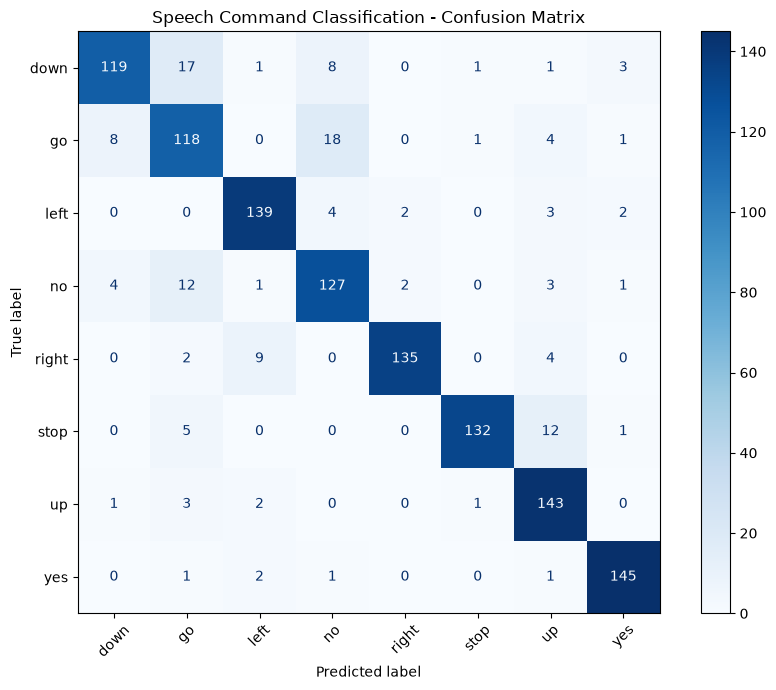

In [50]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Predict test recordings
y_prob = model_v2.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Ground-truth labels in dataset order
y_true = np.concatenate([
    batch_labels.numpy()
    for _, batch_labels in test_ds
])

print("Classification Report:\n")
print(classification_report(
    y_true, y_pred,
    labels=np.arange(len(commands)),
    target_names=commands,
    digits=3
))

# Plot confusion matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(len(commands))
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=commands
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Speech Command Classification - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [51]:

# Choose a WAV file for demonstration
new_audio_path = next((DATASET_PATH / "stop").glob("*.wav"))

# Preprocess
waveform = load_audio(str(new_audio_path))
spec = get_spectrogram(waveform)

# Add batch dimension
spec = tf.expand_dims(spec, axis=0)

# Predict
probabilities = model_v2.predict(spec, verbose=0)[0]

predicted_index = np.argmax(probabilities)
predicted_command = commands[predicted_index]

print("Predicted Command:", predicted_command)
print(f"Confidence: {probabilities[predicted_index] * 100:.2f}%")

display(Audio(waveform.numpy(), rate=16000))


Predicted Command: stop
Confidence: 100.00%


In [52]:

# Save final trained model
model_v2.save("speech_command_cnn.keras")

print("Model saved successfully!")
print("Final Test Accuracy:", f"{test_accuracy * 100:.2f}%")
print("Total Classes:", len(commands))
print("Class Labels:", commands)


Model saved successfully!
Final Test Accuracy: 88.17%
Total Classes: 8
Class Labels: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']


## Conclusion — Speech Command Classification Using TensorFlow

**Objective:** Develop a CNN-based speech recognition system to classify eight spoken commands: down, go, left, no, right, stop, up and yes.

**Dataset:** TensorFlow Mini Speech Commands dataset containing 8,000 audio recordings, with 1,000 recordings per class.

**Methodology:**
- Loaded WAV recordings and standardized their lengths.
- Converted audio waveforms into spectrograms using Short-Time Fourier Transform (STFT).
- Created stratified training (70%), validation (15%) and testing (15%) datasets.
- Developed and compared two CNN architectures using TensorFlow and Keras.
- Evaluated the improved model using accuracy, loss, confusion matrix and classification metrics.

### Results

| Metric | Result |
|---|---|
| Model V1 best validation accuracy | 54.00% |
| Model V2 best validation accuracy | 89.92% |
| Model V2 test accuracy | 88.17% |
| Model V2 test loss | 0.4645 |
| Final model parameters | 261,704 |

**Conclusion:** The improved CNN achieved 88.17% accuracy on the held-out test recordings. This project demonstrates how audio signals can be transformed into spectrograms and classified using convolutional neural networks.

**Limitations:** Results were obtained on a small command-vocabulary dataset. Performance on noisy environments, unfamiliar microphones and completely new speakers requires further evaluation.

**Future improvements:** Test audio augmentation, log-magnitude spectrograms, speaker-independent evaluation and real-time microphone inference.

**Reference:** [TensorFlow — Simple Audio Recognition](https://www.tensorflow.org/tutorials/audio/simple_audio)